# Week 3 LAB PRACTICAL SHEET
## Sobel Edge Detection Using Python OpenCV

### PART A

**Task 1: Install Required Libraries**

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

### PART B – Read and Display an Image

**Task 2: Load an Image**

Select a suitable image containing clearly visible objects and boundaries.

In [5]:
image = cv2.imread("Images/Image25.jpg")
cv2.imshow("Original Image", image)
cv2.waitKey(0)
cv2.destroyAllWindows()

**Self-study Questions**

1. What information is stored in the variable `image`?
   > It stores a multi-dimensional NumPy array representing the image pixel data. For a standard color image, it is a 3D array of dimensions $\text{height} \times \text{width} \times 3$, containing pixel values from $0$ to $255$.
2. What colour representation does OpenCV use by default?
   > OpenCV uses the BGR (Blue, Green, Red) color model by default instead of RGB.
3. Why is edge detection normally performed on a grayscale image?
   > Edge detection identifies intensity changes and sharp transitions. Grayscale simplifies the data to a single intensity channel, drastically reducing computational complexity while retaining structural and boundary information.

### PART C – Convert the Image to Grayscale

**Task 3: Grayscale Conversion**

Convert the colour image into grayscale.

In [6]:
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
cv2.imshow("Grayscale Image", gray)
cv2.waitKey(0)
cv2.destroyAllWindows()

**Observation**

Compare the original image and grayscale image.

| Property | Original Image | Grayscale Image |
| --- | --- | --- |
| Image dimensions | Height x Width x 3 | Height x Width |
| Number of channels | 3 (BGR) | 1 (grayscale) |
| Pixel intensity range | 0-255 per channel | 0-255 |

**Self-study Questions**

1. What is the range of pixel values in an 8-bit grayscale image?
   > The values range from $0$ to $255$, where $0$ represents black and $255$ represents white.
2. Why does grayscale conversion reduce computational requirements?
   > A color image processes 3 channels (BGR), whereas a grayscale image processes only 1 channel. Converting reduces data size and mathematical calculations by $66.7\%$.

### PART D – Apply Sobel Edge Detection
**Task 4: Detect Vertical Edges**

Apply the Sobel operator along the X-direction.

In [7]:
sobel_x = cv2.Sobel(
gray,
cv2.CV_64F, #Convert to 64-bit floating point
1, # dx
0, # dy
ksize=3
)
cv2.imshow("Sobel X", cv2.convertScaleAbs(sobel_x))
cv2.waitKey(0)
cv2.destroyAllWindows()

**Explanation**

The parameters:

- `dx = 1`
- `dy = 0`

indicate that the derivative is calculated in the X-direction.

**Self-study Questions**

1. Which type of edges appear more prominently?
   > Vertical edges appear most prominently because the derivative calculation is targeted along the X-direction ($dx=1, dy=0$).
2. What is the purpose of `cv2.CV_64F`?
   > It uses 64-bit floating-point precision to store negative gradient values generated when transitioning from bright-to-dark pixels. Standard 8-bit unsigned integers (`uint8`) truncate negative values to zero, which would cause half of the edges to be lost.
3. Why is `convertScaleAbs()` applied before displaying the result?
   > It takes the absolute value of the gradients (turning negative gradients positive) and converts the data back to an 8-bit `uint8` range ($0\text{–}255$) so it can be visualised properly.

### PART E – Detect Horizontal Edges

**Task 5: Sobel Y**

Apply Sobel in the Y-direction.

In [8]:
sobel_y = cv2.Sobel(
    gray,
    cv2.CV_64F,
    0, # dx
    1, # dy
    ksize=3
)
cv2.imshow("Sobel Y", cv2.convertScaleAbs(sobel_y))
cv2.waitKey(0)
cv2.destroyAllWindows()

**Self-study Questions**

1. Which edges are highlighted by Sobel Y?
   > Horizontal edges are highlighted.
2. Compare the result with Sobel X.
   > Sobel X highlights vertical boundaries (left-to-right intensity transitions), whereas Sobel Y highlights horizontal boundaries (top-to-bottom intensity transitions).
3. Explain why different edges appear in the two images.
   > The Sobel X operator uses a horizontal derivative kernel to compute changes across columns, while the Sobel Y operator uses a vertical derivative kernel to compute changes across rows.

### PART F – Combine X and Y Gradients

**Task 6: Combined Sobel Image**

Convert both derivative images to absolute values.

In [9]:
sobel_x_abs = cv2.convertScaleAbs(sobel_x)
sobel_y_abs = cv2.convertScaleAbs(sobel_y)
sobel_combined = cv2.addWeighted(
    sobel_x_abs,
    0.5,
    sobel_y_abs,
    0.5,
    0
)
cv2.imshow("Combined Sobel", sobel_combined)
cv2.waitKey(0)
cv2.destroyAllWindows()

**Self-study Questions**

1. Why are Sobel X and Sobel Y combined?
   > To create a complete representation of object boundaries, as real-world images contain edges oriented in all directions.
2. What is the purpose of the weights 0.5 and 0.5?
   > They specify equal $50\%$ contributions from both horizontal and vertical edge maps to ensure balanced scaling without exceeding the $0\text{–}255$ range.
3. Does the combined image contain more complete object boundaries?
   > Yes, it combines both horizontal and vertical spatial structural features.

### PART G – Calculate Gradient Magnitude

**Task 7: Mathematical Gradient Magnitude**

Calculate the magnitude using:

$$
G = \sqrt{G_x^2 + G_y^2}
$$

In [10]:
gradient_magnitude = np.sqrt(
sobel_x ** 2 + sobel_y ** 2
)
gradient_magnitude = cv2.convertScaleAbs(
gradient_magnitude
)
cv2.imshow(
    "Gradient Magnitude",
gradient_magnitude
)
cv2.waitKey(0)
cv2.destroyAllWindows()

**Self-study Questions**

1. What does gradient magnitude represent?
   > It represents the true total rate of change in pixel intensity at every point, independent of edge direction.
2. What does a large gradient value indicate?
   > A sharp intensity change, indicating a prominent physical edge or boundary.
3. Compare this result with the output obtained using `cv2.addWeighted()`.
   > `cv2.addWeighted()` provides a fast linear approximation ($0.5\vert{}G_x\vert{} + 0.5\vert{}G_y\vert{}$), whereas true gradient magnitude uses Euclidean distance ($\sqrt{G_x^2 + G_y^2}$) which is mathematically precise and rotation-invariant.

### PART H – Display All Results Using Matplotlib

**Task 8: Comparative Visualisation**

Use Matplotlib to display all processing stages.

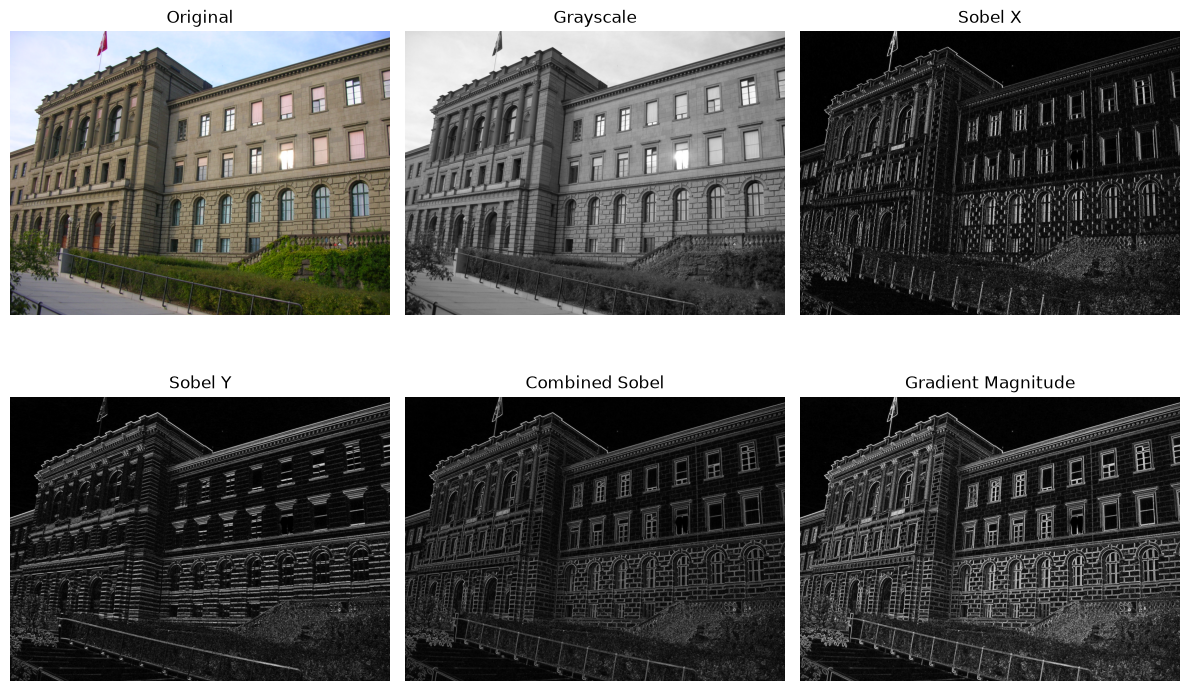

In [11]:
plt.figure(figsize=(12, 8))
plt.subplot(2, 3, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original")
plt.axis("off")
plt.subplot(2, 3, 2)
plt.imshow(gray, cmap="gray")
plt.title("Grayscale")
plt.axis("off")
plt.subplot(2, 3, 3)
plt.imshow(sobel_x_abs, cmap="gray")
plt.title("Sobel X")
plt.axis("off")
plt.subplot(2, 3, 4)
plt.imshow(sobel_y_abs, cmap="gray")
plt.title("Sobel Y")
plt.axis("off")
plt.subplot(2, 3, 5)
plt.imshow(sobel_combined, cmap="gray")
plt.title("Combined Sobel")
plt.axis("off")
plt.subplot(2, 3, 6)
plt.imshow(gradient_magnitude, cmap="gray")
plt.title("Gradient Magnitude")
plt.axis("off")
plt.tight_layout()
plt.show()

### PART I – Effect of Kernel Size

**Task 9: Experiment with Different Kernel Sizes**

Run Sobel using:

- `ksize = 1`
- `ksize = 3`
- `ksize = 5`
- `ksize = 7`

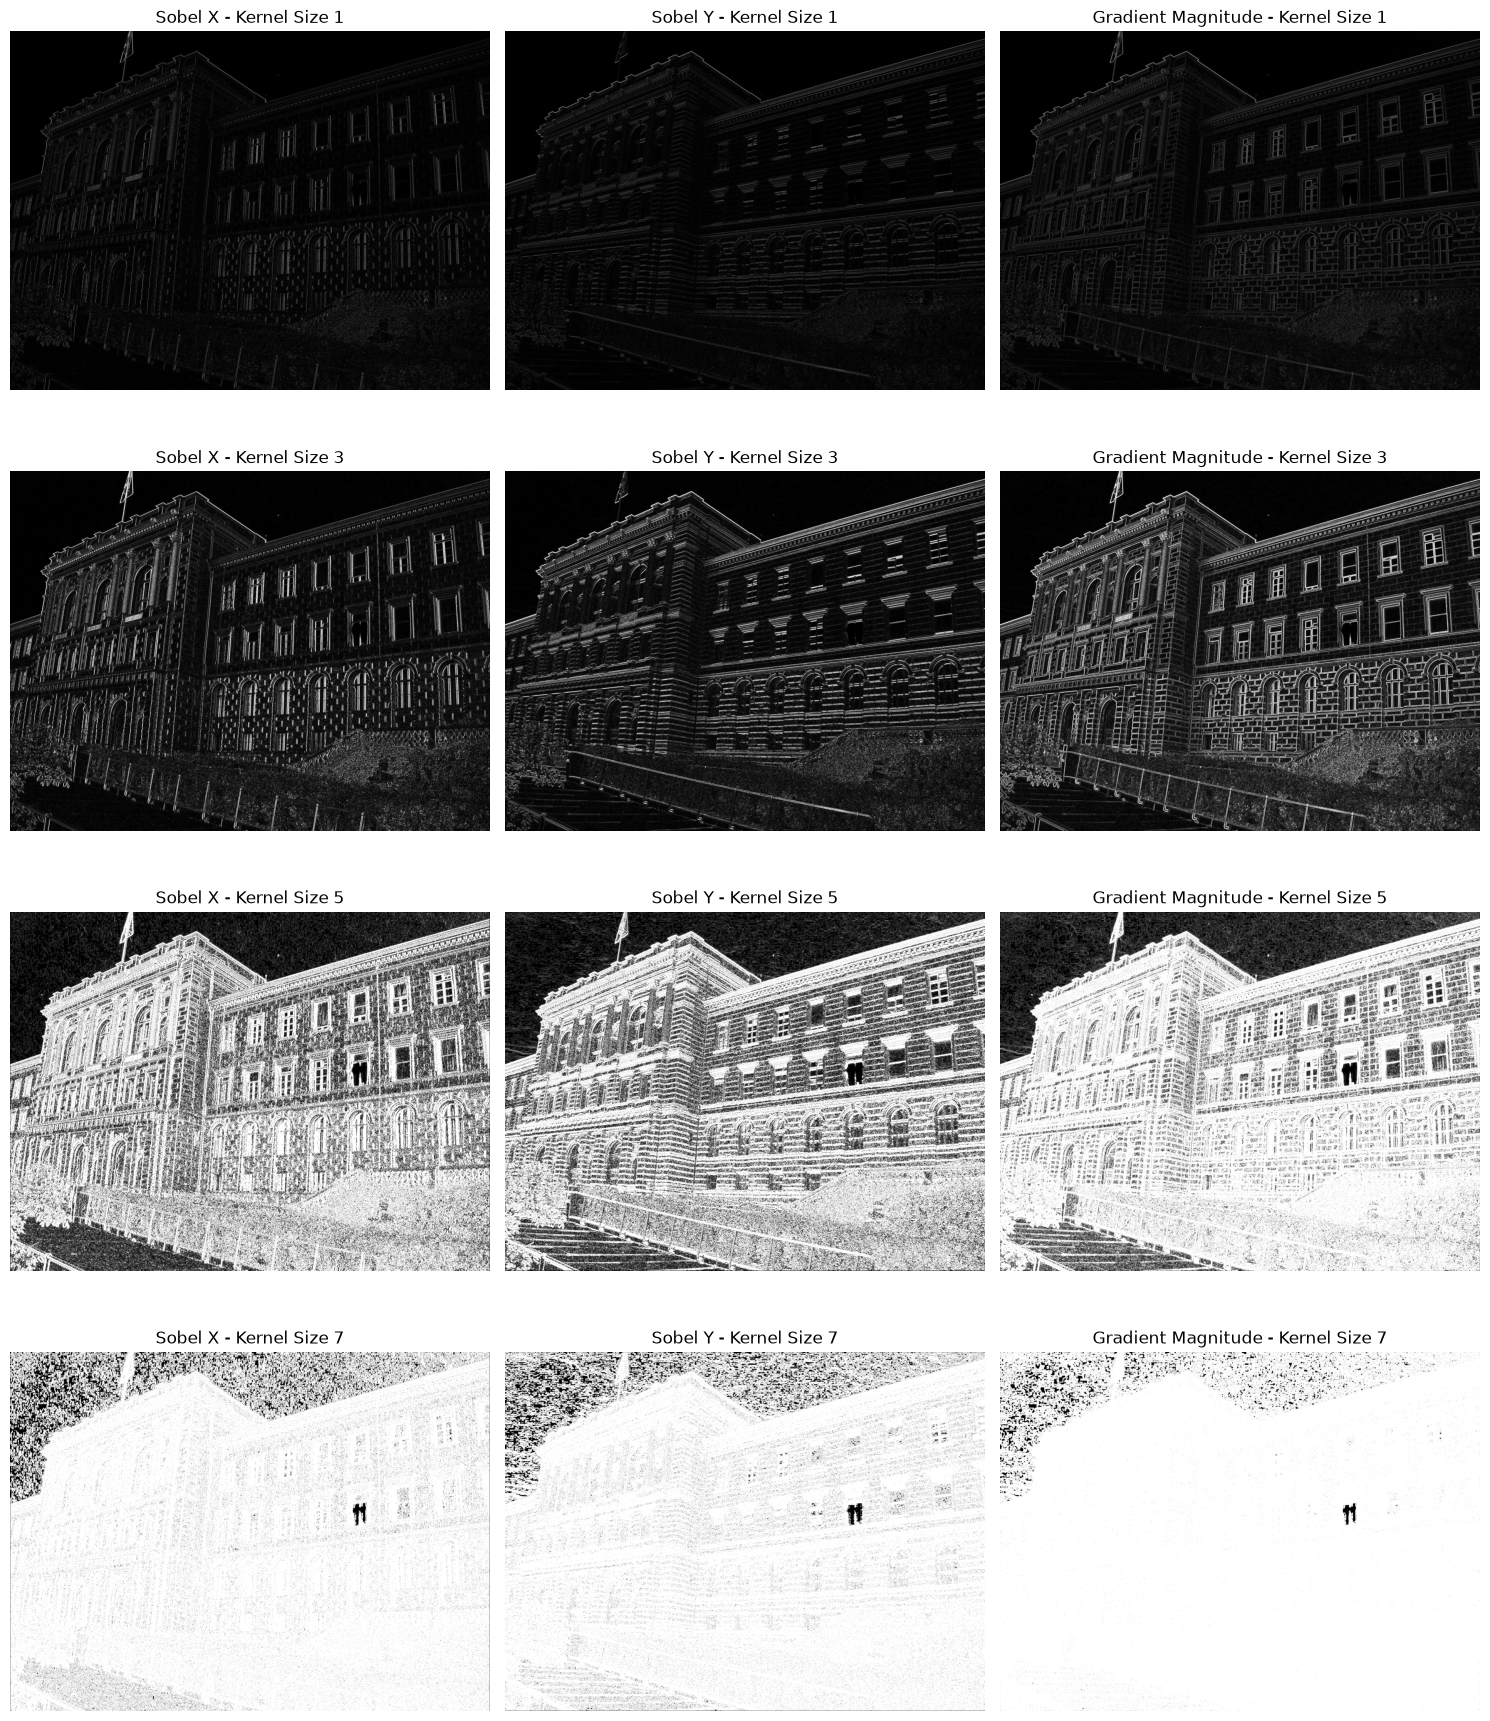

In [12]:
kernel_sizes = [1, 3, 5, 7]

fig, axes = plt.subplots(4, 3, figsize=(15, 18))

for row, kernel_size in enumerate(kernel_sizes):
    sobel_x_kernel = cv2.Sobel(
        gray,
        cv2.CV_64F,
        1,
        0,
        ksize=kernel_size
    )
    sobel_y_kernel = cv2.Sobel(
        gray,
        cv2.CV_64F,
        0,
        1,
        ksize=kernel_size
    )

    sobel_x_kernel_abs = cv2.convertScaleAbs(sobel_x_kernel)
    sobel_y_kernel_abs = cv2.convertScaleAbs(sobel_y_kernel)
    gradient_magnitude_kernel = cv2.convertScaleAbs(
        np.sqrt(sobel_x_kernel ** 2 + sobel_y_kernel ** 2)
    )

    outputs = [
        sobel_x_kernel_abs,
        sobel_y_kernel_abs,
        gradient_magnitude_kernel
    ]
    titles = [
        f"Sobel X - Kernel Size {kernel_size}",
        f"Sobel Y - Kernel Size {kernel_size}",
        f"Gradient Magnitude - Kernel Size {kernel_size}"
    ]

    for column, (output, title) in enumerate(zip(outputs, titles)):
        axes[row, column].imshow(output, cmap="gray")
        axes[row, column].set_title(title)
        axes[row, column].axis("off")

plt.tight_layout()
plt.show()

**Compare the results.**

| Kernel Size | Edge Detail | Edge Thickness | Noise Sensitivity | Observation |
| --- | --- | --- | --- | --- |
| 1 | Very high | Very thin | Very high | Preserves fine details but produces a noisy edge map. |
| 3 | High | Thin | High | Provides a good balance between edge detail and noise reduction. |
| 5 | Moderate | Moderate | Moderate | Smooths noise while retaining the main object boundaries. |
| 7 | Low | Thick | Low | Produces the smoothest result but loses fine edge details. |

**Self-study Questions**

1. What happens when the kernel size increases?
   > Larger kernels average over bigger pixel neighborhoods. This suppresses noise and creates thicker, smoother edge responses, but fine details are lost.
2. Which kernel provides the best result for your image?
   > Typically, `ksize=3` offers the best balance between suppressing noise and retaining detailed edges.
3. Is a larger kernel always better? Explain.
   > No. While larger kernels reduce noise, they blur sharp structural details and merge closely spaced edges together.

### PART J – Effect of Noise

**Task 10: Add Noise to the Image**

Generate a noisy image:

In [13]:
noise = np.random.normal(
    0,
    25,
    gray.shape
)

noisy_image = gray.astype(np.float64) + noise

noisy_image = np.clip(
    noisy_image,
    0,
    255
).astype(np.uint8)

noisy_sobel = cv2.Sobel(
    noisy_image,
    cv2.CV_64F,
    1,
    0,
    ksize=3
)

noisy_sobel = cv2.convertScaleAbs(
    noisy_sobel
)

cv2.imshow("Noisy Image", noisy_image)
cv2.imshow("Sobel on Noisy Image", noisy_sobel)
cv2.waitKey(0)
cv2.destroyAllWindows()

**Self-study Questions**

1. How does noise affect Sobel Edge Detection?
   > Sobel is a derivative operator, which amplifies high-frequency variations like pixel noise.
2. Why are false edges produced?
   > Random intensity spikes caused by noise are misinterpreted as sharp contrast changes.
3. Suggest a technique that could reduce this problem.
   > Apply a spatial smoothing filter, such as a Gaussian filter or Median filter, prior to edge detection.

### PART K – Gaussian Smoothing Before Sobel

**Task 11: Reduce Noise**

Apply Gaussian smoothing before performing Sobel Edge Detection.

In [14]:
blurred = cv2.GaussianBlur(
    noisy_image,
    (5, 5),
    0
)
sobel_blurred = cv2.Sobel(
    blurred,
    cv2.CV_64F,
    1,
    0,
    ksize=3
)
sobel_blurred = cv2.convertScaleAbs(
    sobel_blurred
)
cv2.imshow("Blurred Image", blurred)
cv2.imshow(
    "Sobel after Gaussian Blur",
    sobel_blurred
)
cv2.waitKey(0)
cv2.destroyAllWindows()

**Compare the 3 processes:**

- Original Image → Sobel
- Noisy Image → Sobel
- Noisy Image → Gaussian Blur → Sobel

**Comparison:**

The original image followed by Sobel produces clear edges with relatively little noise. Applying Sobel directly to the noisy image produces many extra false edges because Sobel amplifies rapid intensity changes caused by noise. Applying Gaussian blur before Sobel reduces these false edges and produces a cleaner, more stable edge map. However, excessive smoothing can blur genuine boundaries and remove fine details. Therefore, the Gaussian-blur pipeline generally gives the best balance between noise reduction and edge preservation.

**Self-study Questions**

1. Did Gaussian smoothing reduce false edges?
   > Yes, by blurring high-frequency random noise prior to computing derivatives.
2. What disadvantage may occur when excessive smoothing is used?
   > True edge boundaries become blurred, less localized, and fine structural details disappear.
3. Why is smoothing commonly performed before edge detection?
   > Edge detection filters are sensitive to noise; pre-smoothing removes spurious noise spikes so derivatives reflect actual object contours.

### PART L – Threshold the Sobel Result

**Task 12: Produce a Binary Edge Map**

Apply thresholding to the gradient magnitude.

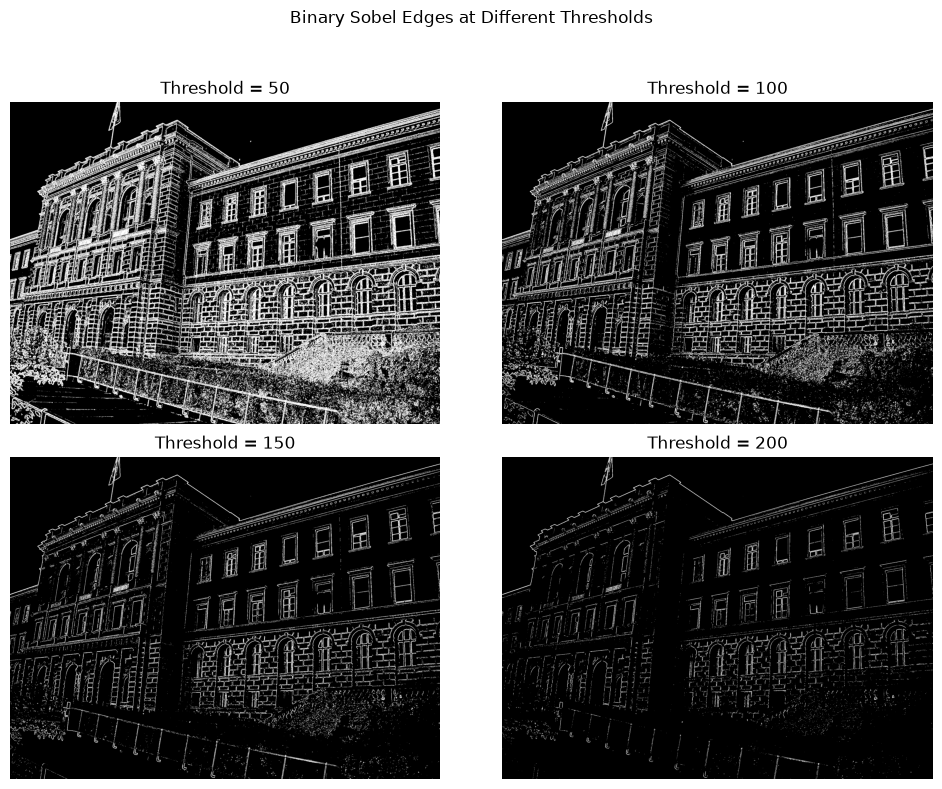

In [15]:
threshold_values = [50, 100, 150, 200]

figure, axes = plt.subplots(2, 2, figsize=(10, 8))

for axis, threshold_value in zip(axes.flat, threshold_values):
    _, binary_edges = cv2.threshold(
        gradient_magnitude,
        threshold_value,
        255,
        cv2.THRESH_BINARY
    )
    axis.imshow(binary_edges, cmap="gray")
    axis.set_title(f"Threshold = {threshold_value}")
    axis.axis("off")

figure.suptitle("Binary Sobel Edges at Different Thresholds")
figure.tight_layout(rect=(0, 0, 1, 0.94), h_pad=2.0)
plt.show()

Experiment with threshold values such as:

- 50
- 100
- 150
- 200

| Threshold | Number/Visibility of Edges | Noise | Observation |
| --- | --- | --- | --- |
| 50 | Very high; many fine edges are visible. | High | Detects most building details, but the edge map is cluttered by background texture and weak edges. |
| 100 | High; main and many fine edges remain visible. | Moderate | Provides a good balance between preserving building boundaries and reducing unwanted edges. |
| 150 | Moderate; mainly stronger edges are visible. | Low | Removes many weak edges and background details, producing a cleaner but less detailed edge map. |
| 200 | Low; only the strongest edges remain. | Very low | Produces the cleanest result, but several weaker building details and boundaries are lost. |

**Self-study Questions**

1. What happens when the threshold is too low?
   > Too many weak gradient fluctuations and background noise are included, resulting in a cluttered binary map.
2. What happens when the threshold is too high?
   > Significant edges are lost, leaving broken lines or missing object boundaries.
3. How would you determine an appropriate threshold automatically?
   > By applying automatic global thresholding techniques such as Otsu's Thresholding (`cv2.THRESH_OTSU`) or adaptive thresholding methods.

### PART M – Student Exercise

**Exercise 1**

Select three different images, preferably containing:

1. Buildings or man-made structures
2. People or objects
3. Natural scenery

For each image:

- Convert to grayscale.
- Apply Sobel X.
- Apply Sobel Y.
- Calculate the combined Sobel output.
- Calculate gradient magnitude.
- Apply thresholding.

Compare the results.

Prepare a table summarising your observations.

In [20]:
import cv2
import numpy as np
import os

# ----------------------------------------------------
# 1. Accept an image filename from the user
# ----------------------------------------------------
filename = input("Enter the image filename (e.g. Image1.jpg): ") #13, 24, 29

# ----------------------------------------------------
# 2. Read the image
# ----------------------------------------------------
image = cv2.imread("Images/" + filename)

# Check whether the image was successfully loaded
if image is None:
    print("Error: Image could not be found or opened.")
    exit()

# ----------------------------------------------------
# 3. Convert the image to grayscale
# ----------------------------------------------------
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# ----------------------------------------------------
# 4. Apply Gaussian smoothing
# ----------------------------------------------------
blurred = cv2.GaussianBlur(gray, (5, 5), 0)

# ----------------------------------------------------
# 5. Calculate Sobel X
# Detects intensity changes in the x-direction
# ----------------------------------------------------
sobel_x = cv2.Sobel(
    blurred,
    cv2.CV_64F,
    1,
    0,
    ksize=3
)

# ----------------------------------------------------
# 6. Calculate Sobel Y
# Detects intensity changes in the y-direction
# ----------------------------------------------------
sobel_y = cv2.Sobel(
    blurred,
    cv2.CV_64F,
    0,
    1,
    ksize=3
)

# Convert Sobel results for display
sobel_x_display = cv2.convertScaleAbs(sobel_x)
sobel_y_display = cv2.convertScaleAbs(sobel_y)

# ----------------------------------------------------
# 7. Calculate gradient magnitude
#
# G = sqrt(Gx^2 + Gy^2)
# ----------------------------------------------------
gradient_magnitude = np.sqrt(
    sobel_x ** 2 + sobel_y ** 2
)

# Normalize gradient magnitude to the range 0-255
gradient_magnitude = cv2.normalize(
    gradient_magnitude,
    None,
    0,
    255,
    cv2.NORM_MINMAX
)

gradient_magnitude = gradient_magnitude.astype(np.uint8)

# ----------------------------------------------------
# 8. Generate a binary edge map
# ----------------------------------------------------
threshold_value = 50

_, binary_edges = cv2.threshold(
    gradient_magnitude,
    threshold_value,
    255,
    cv2.THRESH_BINARY
)

# ----------------------------------------------------
# 9. Display all outputs
# ----------------------------------------------------
cv2.imshow("1 - Original Image", image)
cv2.imshow("2 - Grayscale Image", gray)
cv2.imshow("3 - Gaussian Smoothed Image", blurred)
cv2.imshow("4 - Sobel X", sobel_x_display)
cv2.imshow("5 - Sobel Y", sobel_y_display)
cv2.imshow("6 - Gradient Magnitude", gradient_magnitude)
cv2.imshow("7 - Binary Edge Map", binary_edges)

# ----------------------------------------------------
# 10. Save the final edge image
# ----------------------------------------------------
output_filename = f"Output/sobel_edge_{filename}"

cv2.imwrite(output_filename, binary_edges)

print("Processing completed successfully.")
print("Final edge image saved as:", output_filename)

# Wait for a key press before closing windows
cv2.waitKey(0)
cv2.destroyAllWindows()


Enter the image filename (e.g. Image1.jpg):  Image27.jpg


Processing completed successfully.
Final edge image saved as: Output/sobel_edge_Image27.jpg


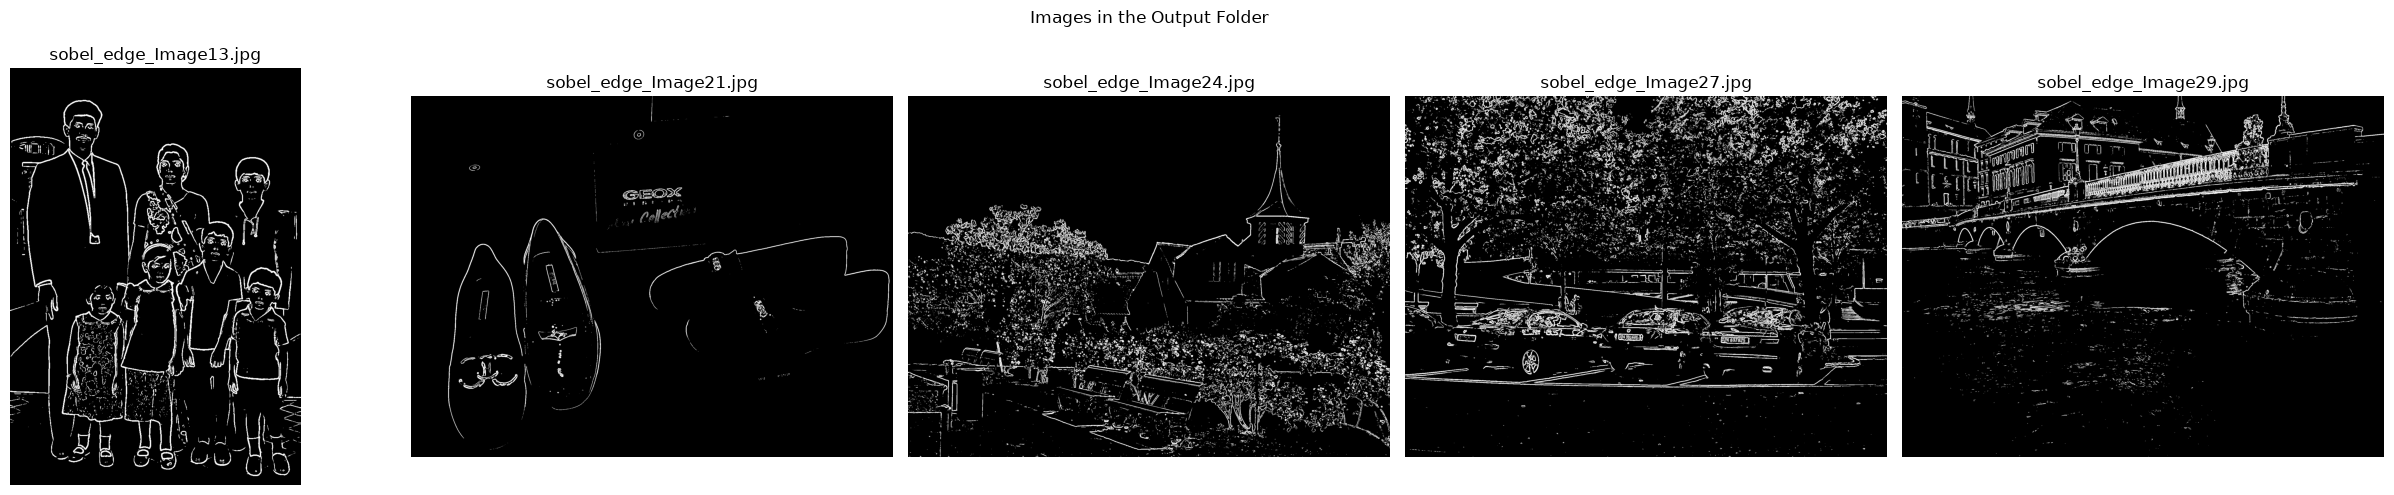

In [21]:
from pathlib import Path

output_folder = Path("Output")
image_paths = sorted(
    path for path in output_folder.iterdir()
    if path.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
)

if not image_paths:
    print(f"No images found in {output_folder.resolve()}")
else:
    figure, axes = plt.subplots(
        1,
        len(image_paths),
        figsize=(5 * len(image_paths), 5),
        squeeze=False
    )
    axes = axes[0]

    for axis, image_path in zip(axes, image_paths):
        output_image = cv2.imread(str(image_path))
        if output_image is None:
            axis.set_title(f"Could not read {image_path.name}")
            axis.axis("off")
            continue

        axis.imshow(cv2.cvtColor(output_image, cv2.COLOR_BGR2RGB))
        axis.set_title(image_path.name)
        axis.axis("off")

    figure.suptitle("Images in the Output Folder")
    figure.tight_layout()
    plt.show()